In [1]:
# Normalization (Min-Max Scaling)
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]
})
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(data)
normalized_df = pd.DataFrame(normalized_data, columns=data.columns)
print("Normalized Data (MinMaxScaler):")
print(normalized_df)

# Standardization (Z-score)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized_data = scaler.fit_transform(data)
standardized_df = pd.DataFrame(standardized_data, columns=data.columns)
print("\nStandardized Data (Z-score):")
print(standardized_df)

# One-Hot Encoding
df = pd.DataFrame({'Color': ['Red', 'Blue', 'Green', 'Red', 'Blue']})
one_hot = pd.get_dummies(df, columns=['Color'])
print("\nOne-Hot Encoding:")
print(one_hot)

Normalized Data (MinMaxScaler):
      A     B
0  0.00  0.00
1  0.25  0.25
2  0.50  0.50
3  0.75  0.75
4  1.00  1.00

Standardized Data (Z-score):
          A         B
0 -1.414214 -1.414214
1 -0.707107 -0.707107
2  0.000000  0.000000
3  0.707107  0.707107
4  1.414214  1.414214

One-Hot Encoding:
   Color_Blue  Color_Green  Color_Red
0       False        False       True
1        True        False      False
2       False         True      False
3       False        False       True
4        True        False      False


Explained variance ratio: [0.9912126 0.0087874]

LDA Result (first 5 rows):
        LD1       LD2  target
0  8.061800 -0.300421       0
1  7.128688  0.786660       0
2  7.489828  0.265384       0
3  6.813201  0.670631       0
4  8.132309 -0.514463       0


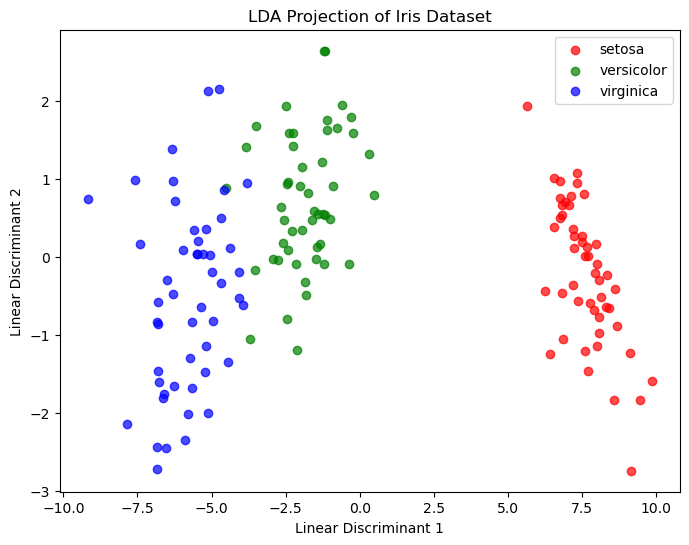

In [2]:
# LDA
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)

lda_df = pd.DataFrame(X_lda, columns=['LD1', 'LD2'])
lda_df['target'] = y

print("Explained variance ratio:", lda.explained_variance_ratio_)
print("\nLDA Result (first 5 rows):")
print(lda_df.head())

plt.figure(figsize=(8, 6))
for label, color in zip([0, 1, 2], ['red', 'green', 'blue']):
    plt.scatter(
        lda_df.loc[lda_df['target'] == label, 'LD1'],
        lda_df.loc[lda_df['target'] == label, 'LD2'],
        label=iris.target_names[label],
        color=color,
        alpha=0.7
    )
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.title('LDA Projection of Iris Dataset')
plt.legend()
plt.show()

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


t-SNE Result (first 5 rows):
       TSNE1     TSNE2  target
0 -23.875437 -1.430589       0
1 -21.332832 -2.522965       0
2 -21.183956 -1.316485       0
3 -20.842545 -1.611920       0
4 -23.845785 -0.945733       0


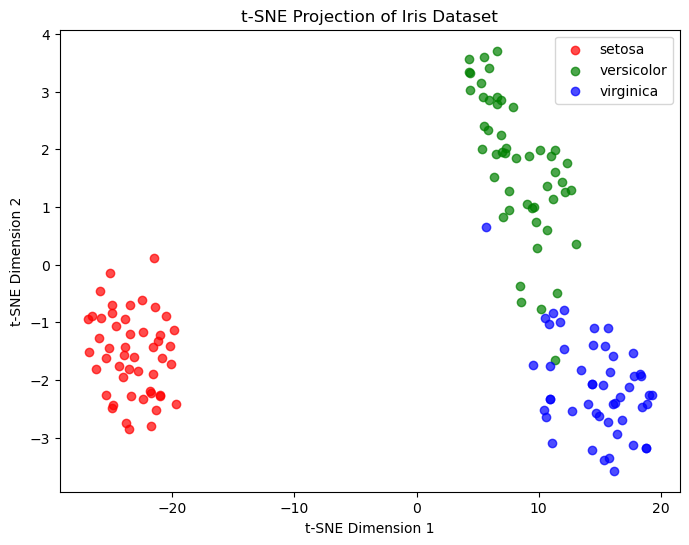

In [3]:
# t-SNE
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target

tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X)

tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['target'] = y

print("t-SNE Result (first 5 rows):")
print(tsne_df.head())

plt.figure(figsize=(8, 6))
for label, color in zip([0, 1, 2], ['red', 'green', 'blue']):
    plt.scatter(
        tsne_df.loc[tsne_df['target'] == label, 'TSNE1'],
        tsne_df.loc[tsne_df['target'] == label, 'TSNE2'],
        label=iris.target_names[label],
        color=color,
        alpha=0.7
    )
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('t-SNE Projection of Iris Dataset')
plt.legend()
plt.show()